# 22 — K-Means Clustering (Clustering Track)
**23CSE301 Machine Learning — Capstone, Review 2**

**Dataset:** Customer Personality Analysis (`marketing_campaign.csv`) — 2,240 customers of a retail company
**Task:** unsupervised customer segmentation — **there is no target column to predict**

| Block | Rubric section |
|---|---|
| 1 | Section A — Dataset & EDA |
| 2 | Section B — Preprocessing & Feature Engineering |
| 3 | Review 2, Section B — Clustering Track (K-Means) |

K-Means places **k** centroids and repeats two steps until nothing moves: assign every customer to the nearest centroid, then move each centroid to the mean of the points assigned to it. It minimises within-cluster squared distance, which makes it fast and makes its clusters roughly spherical and similar in size. The one decision it cannot make for itself is **k**, so the **Elbow curve** and the three validity indices below are used to choose it.

> **Rule for this track (guideline 3.3):** the labels that exist in this dataset (`Response`, the campaign
> acceptance flags) are **never** used while fitting. They are only brought back at the end, to interpret
> whether the segments the algorithm found mean anything commercially.

---
# BLOCK 1 — Dataset & EDA (Section A)

In [1]:
# ============================================================
# BLOCK 1 : DATASET & EDA
# ============================================================

# ---- 1.0 Imports & global settings ----
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
RANDOM_STATE = 42                      # fixed seed for reproducibility (guideline 7.1)
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", palette="colorblind")   # colour-blind-friendly palette (guideline 7.3)
pd.set_option("display.max_columns", 60)

DATA_PATH = "../data/marketing_campaign.csv"   # change if your file is somewhere else

**Note on the file format:** the Kaggle download is **tab-separated**, while some mirrors ship the same data
semicolon-separated. The loader below detects the separator instead of assuming one, so the notebook runs on either copy.

In [2]:
# ---- 1.1 Load the dataset (separator auto-detected) ----
with open(DATA_PATH, encoding="utf-8-sig") as fh:
    header = fh.readline()
sep = max(["\t", ";", ","], key=header.count)
print("Detected separator:", repr(sep))

df = pd.read_csv(DATA_PATH, sep=sep, encoding="utf-8-sig")
print("Shape (rows, columns):", df.shape)
df.head()

Detected separator: ';'
Shape (rows, columns): (2240, 29)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0


## A1 — Dataset loading & audit

| Group | Columns |
|---|---|
| **Who the customer is** | `Year_Birth`, `Education`, `Marital_Status`, `Income`, `Kidhome`, `Teenhome`, `Dt_Customer` |
| **What they spend on (2 years)** | `MntWines`, `MntFruits`, `MntMeatProducts`, `MntFishProducts`, `MntSweetProducts`, `MntGoldProds` |
| **How they buy** | `NumDealsPurchases`, `NumWebPurchases`, `NumCatalogPurchases`, `NumStorePurchases`, `NumWebVisitsMonth` |
| **Campaign response** | `AcceptedCmp1`–`AcceptedCmp5`, `Response`, `Complain` — **held back for post-hoc interpretation only** |
| **Constants** | `Z_CostContact`, `Z_Revenue` — same value for every row |

In [3]:
# ---- 1.2 Data types, missing values, duplicates & constant columns ----
audit = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isnull().sum(),
    "missing_%": (df.isnull().mean() * 100).round(2),
    "n_unique": df.nunique(),
})
print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate rows ignoring the ID column:", df.drop(columns=["ID"]).duplicated().sum())
print("Constant columns:", [c for c in df.columns if df[c].nunique() == 1])
audit

Exact duplicate rows: 0
Duplicate rows ignoring the ID column: 182
Constant columns: ['Z_CostContact', 'Z_Revenue']


,dtype,missing_count,missing_%,n_unique
ID,int64,0,0.00,2240
Year_Birth,int64,0,0.00,59
Education,str,0,0.00,5
Marital_Status,str,0,0.00,8
Income,float64,24,1.07,1974
Kidhome,int64,0,0.00,3
Teenhome,int64,0,0.00,3
Dt_Customer,str,0,0.00,663
Recency,int64,0,0.00,100
MntWines,int64,0,0.00,776


**📝 What this shows:** 182 customers are exact duplicates once the ID column is ignored, `Income` is missing for 24 people (1.1%), and `Z_CostContact` and `Z_Revenue` hold the same value for every row, so they carry no information at all.

In [4]:
# ---- 1.3 Statistical summary of the numeric columns ----
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
ID,2240.0,5592.16,3246.66,0.0,2828.25,5458.5,8427.75,11191.0
Year_Birth,2240.0,1968.81,11.98,1893.0,1959.00,1970.0,1977.00,1996.0
Income,2216.0,52247.25,25173.08,1730.0,35303.00,51381.5,68522.00,666666.0
Kidhome,2240.0,0.44,0.54,0.0,0.00,0.0,1.00,2.0
Teenhome,2240.0,0.51,0.54,0.0,0.00,0.0,1.00,2.0
Recency,2240.0,49.11,28.96,0.0,24.00,49.0,74.00,99.0
MntWines,2240.0,303.94,336.60,0.0,23.75,173.5,504.25,1493.0
MntFruits,2240.0,26.30,39.77,0.0,1.00,8.0,33.00,199.0
MntMeatProducts,2240.0,166.95,225.72,0.0,16.00,67.0,232.00,1725.0
MntFishProducts,2240.0,37.53,54.63,0.0,3.00,12.0,50.00,259.0


**📝 What this shows:** Spending is wildly uneven — wine averages 304 against a median of 174 and a maximum of 1,493 — and `Income` runs from 1,730 up to 666,666, which is not a real salary.

## A2 — EDA visualisations

There is no target distribution to plot in an unsupervised problem, so the equivalent first question is
**how the customers are spread out** — that spread is exactly what the clustering has to carve up.

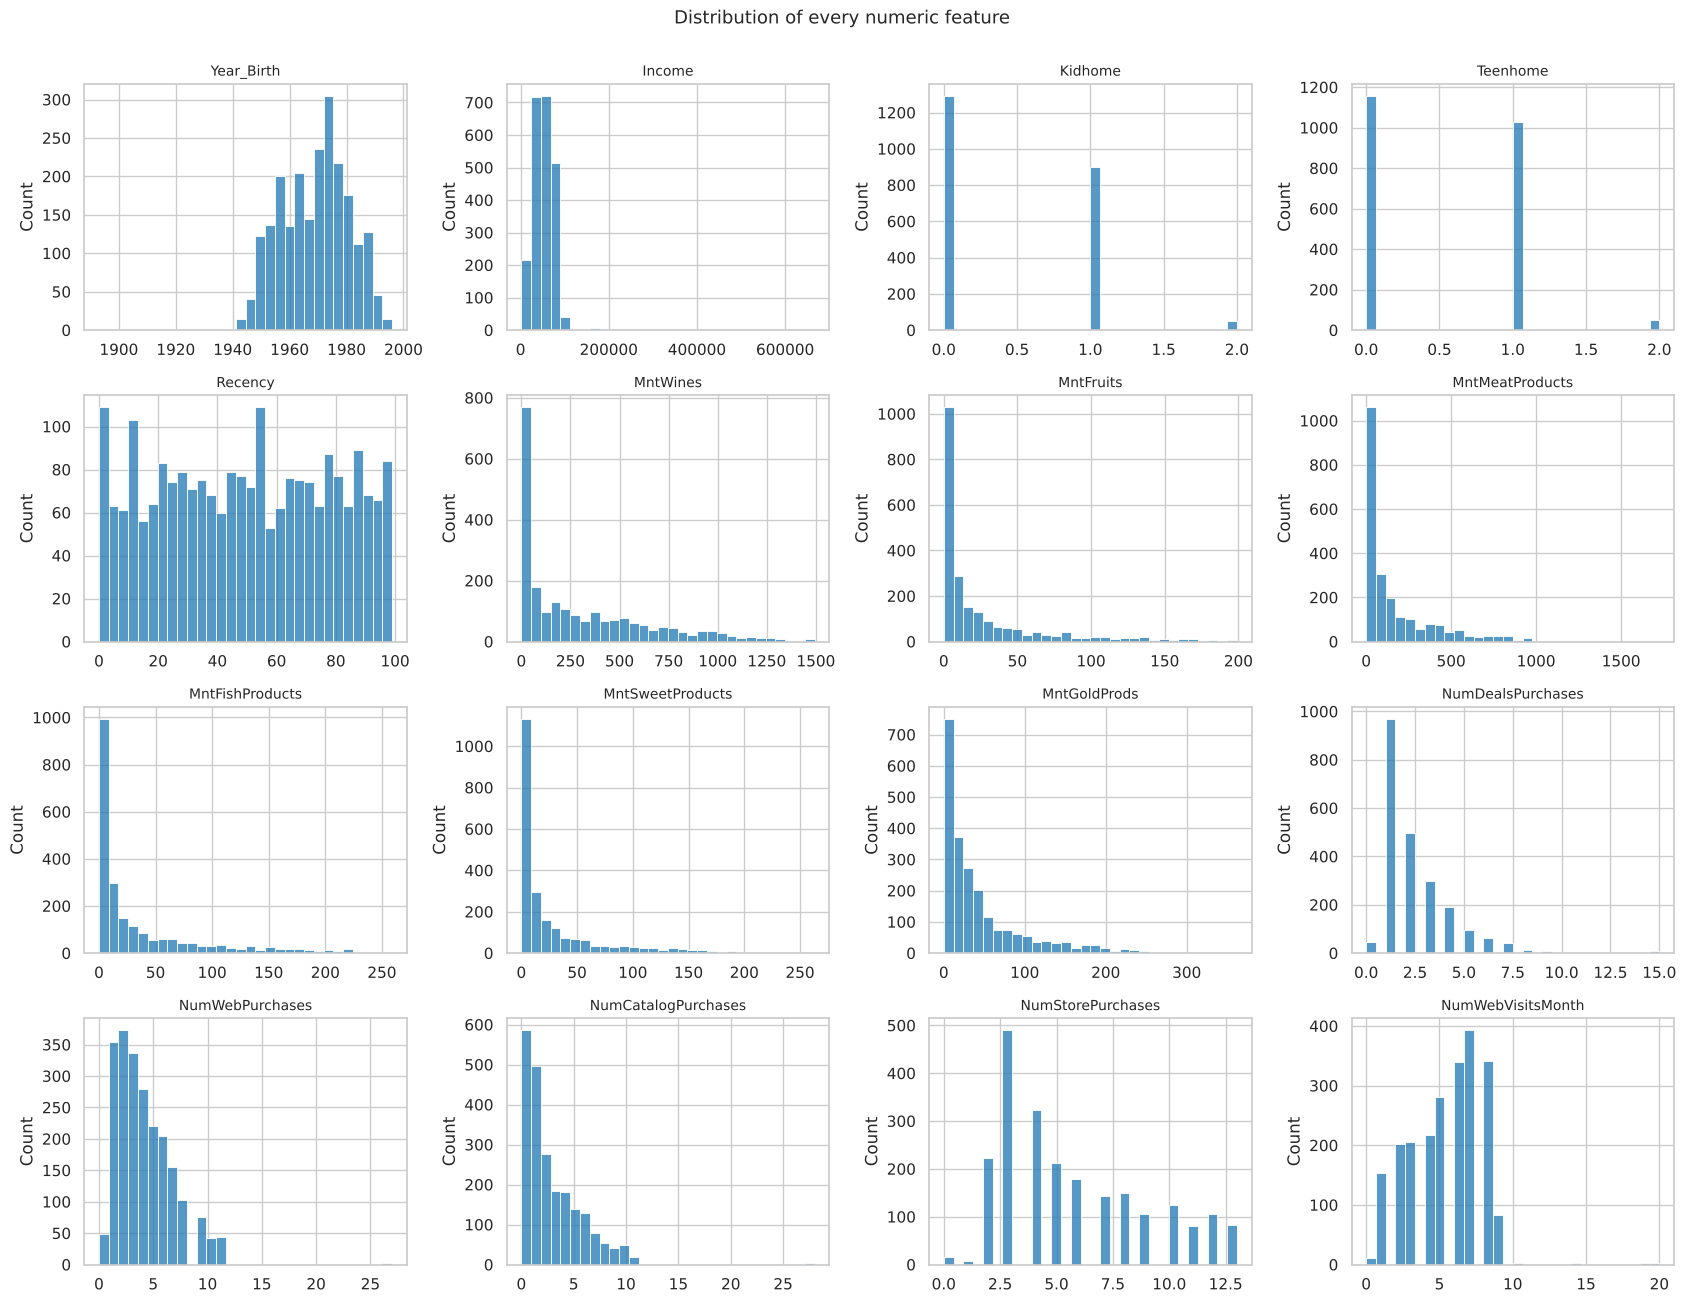

Skewness of the spending columns:
MntWines            1.18
MntFruits           2.10
MntMeatProducts     2.08
MntFishProducts     1.92
MntSweetProducts    2.14
MntGoldProds        1.89
dtype: float64


In [5]:
# ---- 1.4 Distribution of each numeric feature ----
raw_num = ["Year_Birth", "Income", "Kidhome", "Teenhome", "Recency", "MntWines", "MntFruits",
           "MntMeatProducts", "MntFishProducts", "MntSweetProducts", "MntGoldProds",
           "NumDealsPurchases", "NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases",
           "NumWebVisitsMonth"]

fig, axes = plt.subplots(4, 4, figsize=(17, 13))
for ax, col in zip(axes.flat, raw_num):
    sns.histplot(df[col].dropna(), bins=30, ax=ax, color="tab:blue")
    ax.set_title(col, fontsize=10); ax.set_xlabel(""); ax.set_ylabel("Count")
plt.suptitle("Distribution of every numeric feature", y=1.001, fontsize=13)
plt.tight_layout(); plt.show()

print("Skewness of the spending columns:")
print(df[[c for c in raw_num if c.startswith("Mnt")]].skew().round(2))

**📝 What this shows:** Every spending column is right-skewed (skew 1.2 to 2.1): most customers buy very little while a small group buys a great deal, and that lopsidedness is exactly the structure a segmentation has to capture.

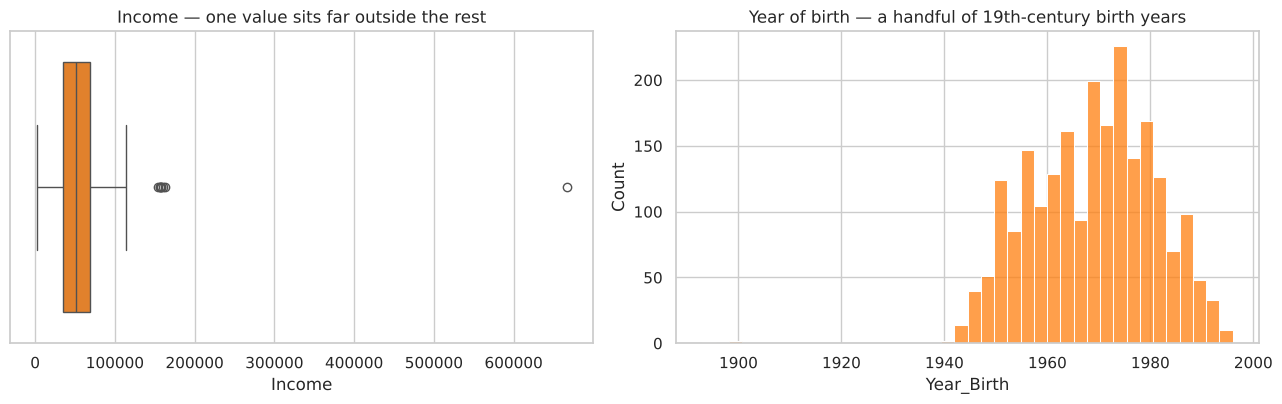

Incomes above 150,000:
 164     157243.0
617     162397.0
655     153924.0
687     160803.0
1300    157733.0
1653    157146.0
2132    156924.0
2233    666666.0

Birth years before 1940:
 192    1900
239    1893
339    1899


In [6]:
# ---- 1.5 The two columns with impossible values ----
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
sns.boxplot(x=df["Income"], ax=axes[0], color="tab:orange")
axes[0].set_title("Income — one value sits far outside the rest")
axes[0].set_xlabel("Income")

sns.histplot(df["Year_Birth"], bins=40, ax=axes[1], color="tab:orange")
axes[1].set_title("Year of birth — a handful of 19th-century birth years")
axes[1].set_xlabel("Year_Birth"); axes[1].set_ylabel("Count")
plt.tight_layout(); plt.show()

print("Incomes above 150,000:\n", df.loc[df["Income"] > 150000, "Income"].to_string())
print("\nBirth years before 1940:\n", df.loc[df["Year_Birth"] < 1940, "Year_Birth"].to_string())

**📝 What this shows:** One customer reports an income of 666,666 against a median of 51,381, and three were born in 1893, 1899 and 1900 — these are data-entry errors, not customers.

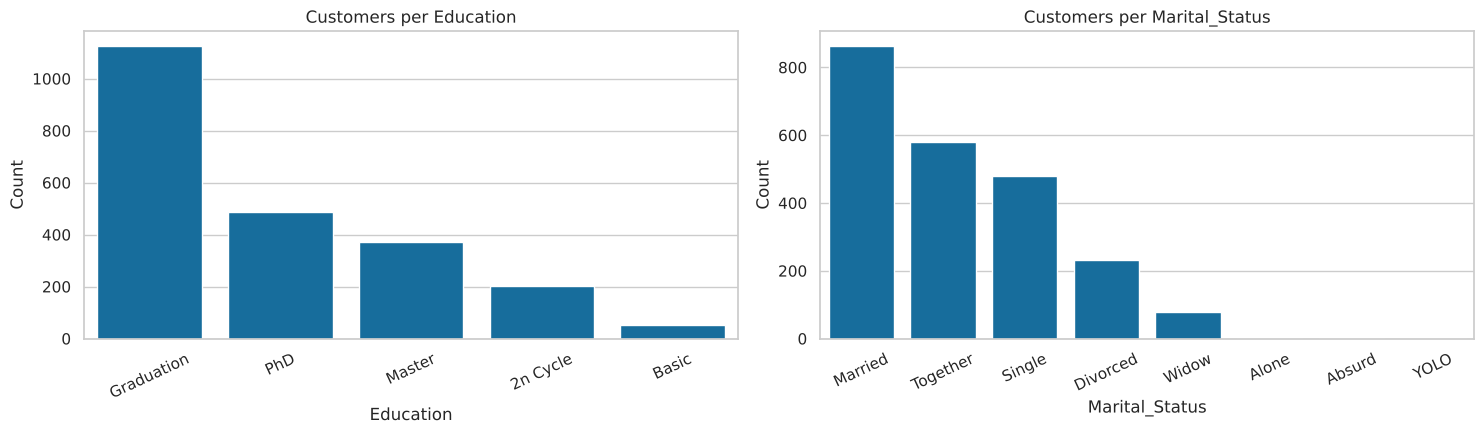

Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
Absurd        2
YOLO          2


In [7]:
# ---- 1.6 Categorical features ----
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, col in zip(axes, ["Education", "Marital_Status"]):
    sns.countplot(data=df, x=col, order=df[col].value_counts().index, ax=ax)
    ax.set_title(f"Customers per {col}")
    ax.set_xlabel(col); ax.set_ylabel("Count"); ax.tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.show()

print(df["Marital_Status"].value_counts().to_string())

**📝 What this shows:** Half the customers are graduates, and `Marital_Status` carries three junk categories — Alone, Absurd and YOLO — covering seven people between them.

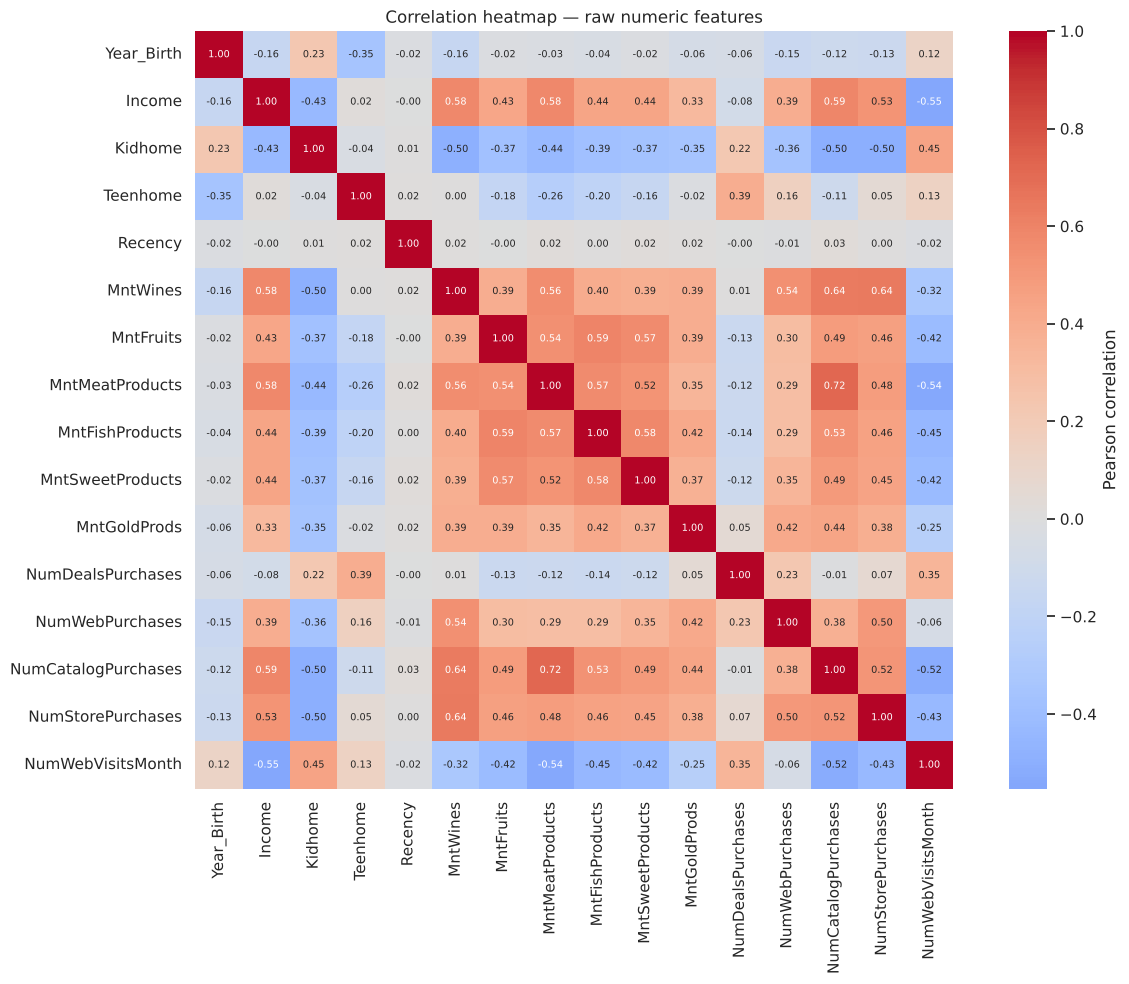

In [8]:
# ---- 1.7 Correlation heatmap ----
plt.figure(figsize=(13, 10))
corr = df[raw_num].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True,
            annot_kws={"size": 7}, cbar_kws={"label": "Pearson correlation"})
plt.title("Correlation heatmap — raw numeric features")
plt.tight_layout(); plt.show()

**📝 What this shows:** Meat spending and catalogue purchases move together most strongly (0.72), income tracks wine and meat spending at about 0.58, and web visits *fall* as income rises (-0.55) — the people browsing the site most often are the ones buying least.

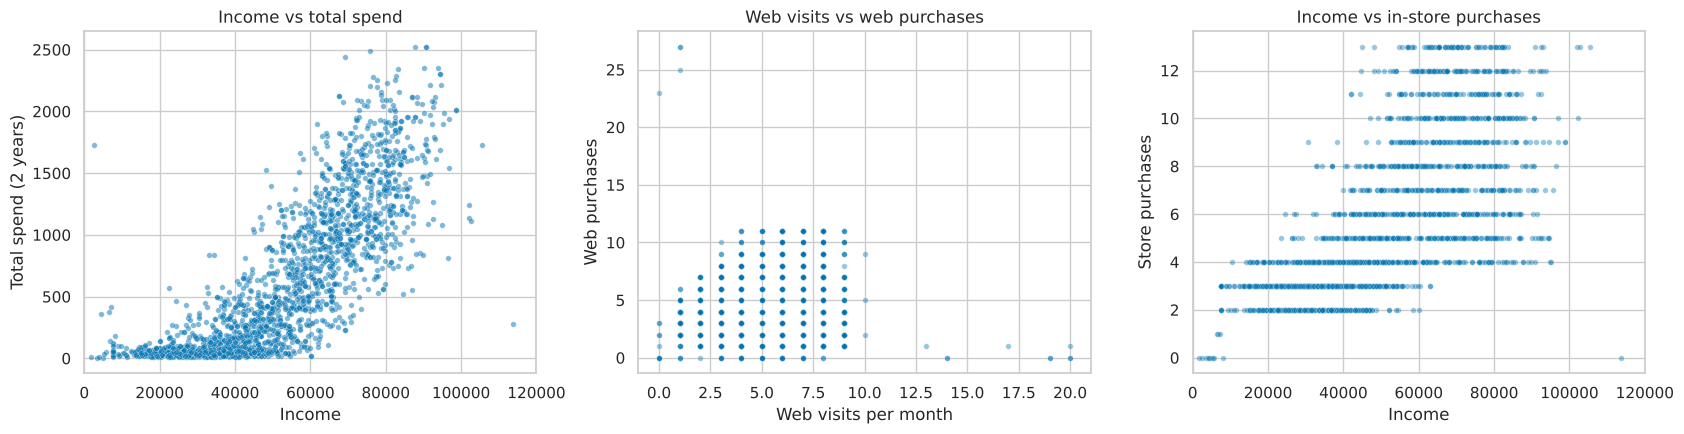

In [9]:
# ---- 1.8 Scatter plots: the relationships a segmentation will hang on ----
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
spend_cols = [c for c in df.columns if c.startswith("Mnt")]
tmp = df.assign(TotalSpend=df[spend_cols].sum(axis=1))

sns.scatterplot(data=tmp, x="Income", y="TotalSpend", alpha=0.5, s=16, ax=axes[0])
axes[0].set_xlim(0, 120000)
axes[0].set_title("Income vs total spend"); axes[0].set_xlabel("Income"); axes[0].set_ylabel("Total spend (2 years)")

sns.scatterplot(data=tmp, x="NumWebVisitsMonth", y="NumWebPurchases", alpha=0.4, s=16, ax=axes[1])
axes[1].set_title("Web visits vs web purchases")
axes[1].set_xlabel("Web visits per month"); axes[1].set_ylabel("Web purchases")

sns.scatterplot(data=tmp, x="Income", y="NumStorePurchases", alpha=0.4, s=16, ax=axes[2])
axes[2].set_xlim(0, 120000)
axes[2].set_title("Income vs in-store purchases")
axes[2].set_xlabel("Income"); axes[2].set_ylabel("Store purchases")
plt.tight_layout(); plt.show()

**📝 What this shows:** Income and total spend rise together but fan out sharply above 60,000, and the middle plot shows the opposite of what you would expect: more web visits go with fewer web purchases.

---
# BLOCK 2 — Preprocessing & Feature Engineering (Section B)

In [10]:
# ============================================================
# BLOCK 2 : PREPROCESSING & FEATURE ENGINEERING
# ============================================================
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# ---- 2.1 Drop the columns that carry no information ----
# Z_CostContact and Z_Revenue are constants; ID is a row identifier.
df = df.drop(columns=["Z_CostContact", "Z_Revenue", "ID"], errors="ignore")

# ---- 2.2 Remove duplicate customers ----
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Duplicates removed: {before - len(df)}  ->  rows now: {len(df)}")

Duplicates removed: 182  ->  rows now: 2058


**Missing-value strategy (justified):**

| Column | Missing | Strategy | Why |
|---|---|---|---|
| `Income` | 24 (1.1%) | fill with the **median income of the same education level** | Dropping 24 paying customers loses real segment members. Income is strongly right-skewed, so the **median** is used rather than the mean, and conditioning on education keeps the imputed values realistic instead of flattening everyone to one number. |

**Outlier strategy — different from the classification track.** In the classification notebooks outliers were *capped*,
because every labelled promotion was worth keeping. Clustering is **not** that forgiving: K-Means minimises squared
distance, so a single customer earning 666,666 drags a centroid towards itself and can own an entire cluster.
The handful of physically impossible rows are therefore **removed**, not capped.

In [11]:
# ---- 2.3 Missing values: income imputed within education level ----
print("Missing before:", df["Income"].isnull().sum())
df["Income"] = df["Income"].fillna(df.groupby("Education")["Income"].transform("median"))
print("Missing after :", int(df.isnull().sum().sum()))

# ---- 2.4 Remove impossible / extreme rows ----
before = len(df)
df = df[(df["Year_Birth"] >= 1940) & (df["Income"] <= 150000)].reset_index(drop=True)
print(f"Rows removed as outliers: {before - len(df)}  ->  rows now: {len(df)}")

Missing before: 24
Missing after : 0
Rows removed as outliers: 11  ->  rows now: 2047


## B3 — Feature engineering

In [12]:
# ---- 2.5 Engineered features ----
# Dt_Customer is parsed with dayfirst=True so both the dd-mm-yyyy (Kaggle) and yyyy-mm-dd (mirror) layouts work.
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], dayfirst=True, format="mixed")
SNAPSHOT = df["Dt_Customer"].max() + pd.Timedelta(days=1)   # the day after the last enrolment = "today"
print("Snapshot date used as 'today':", SNAPSHOT.date())

spend_cols = ["MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts", "MntSweetProducts", "MntGoldProds"]
purchase_cols = ["NumDealsPurchases", "NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]
cmp_cols = ["AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3", "AcceptedCmp4", "AcceptedCmp5"]

df["Age"] = SNAPSHOT.year - df["Year_Birth"]                      # (1) age at the snapshot date
df["Tenure_days"] = (SNAPSHOT - df["Dt_Customer"]).dt.days        # (2) how long they have been a customer
df["TotalSpend"] = df[spend_cols].sum(axis=1)                     # (3) total value over two years
df["TotalPurchases"] = df[purchase_cols].sum(axis=1)              # (4) total transactions
df["Children"] = df["Kidhome"] + df["Teenhome"]                   # (5) children at home
df["Family_Size"] = df["Children"] + df["Marital_Status"].isin(
    ["Married", "Together"]).astype(int) + 1                      # (6) household size
df["AvgOrderValue"] = df["TotalSpend"] / df["TotalPurchases"].replace(0, np.nan)
df["AvgOrderValue"] = df["AvgOrderValue"].fillna(0)               # (7) spend per transaction
df["CampaignsAccepted"] = df[cmp_cols].sum(axis=1)                # (8) HELD BACK — post-hoc only
df["WineShare"] = df["MntWines"] / df["TotalSpend"].replace(0, np.nan)
df["WineShare"] = df["WineShare"].fillna(0)                       # (9) share of wallet going to wine

# tidy the two categorical columns
df["Education_level"] = df["Education"].replace({"2n Cycle": "Master", "Graduation": "Graduate",
                                                 "Basic": "Undergraduate"})
df["Living_With_Partner"] = df["Marital_Status"].isin(["Married", "Together"]).astype(int)

df[["Age", "Tenure_days", "TotalSpend", "TotalPurchases", "Children", "Family_Size",
    "AvgOrderValue", "WineShare"]].describe().T.round(2)

Snapshot date used as 'today': 2014-12-07


,count,mean,std,min,25%,50%,75%,max
Age,2047.0,45.12,11.67,18.0,37.00,44.00,55.00,74.00
Tenure_days,2047.0,512.22,232.58,1.0,340.00,513.00,686.00,1064.00
TotalSpend,2047.0,605.96,601.52,5.0,69.00,397.00,1044.50,2525.00
TotalPurchases,2047.0,14.88,7.60,0.0,8.00,15.00,21.00,43.00
Children,2047.0,0.96,0.75,0.0,0.00,1.00,1.00,3.00
Family_Size,2047.0,2.60,0.91,1.0,2.00,3.00,3.00,5.00
AvgOrderValue,2047.0,33.37,46.30,0.0,9.59,23.50,45.36,1679.00
WineShare,2047.0,0.46,0.23,0.0,0.29,0.46,0.64,0.96


**Why these features may help the clustering:**

- `Age`, `Tenure_days` — raw `Year_Birth` and a date are not distances a clustering algorithm can use; years-old and
  days-enrolled are.
- `TotalSpend`, `TotalPurchases`, `AvgOrderValue` — the classic **monetary / frequency** pair behind RFM segmentation,
  plus basket size, which separates "buys often, spends little" from "buys rarely, spends a lot".
- `Children`, `Family_Size` — `Kidhome` and `Teenhome` on their own split a signal that marketing treats as one.
- `WineShare` — wine is 50% of all spending in this dataset, so the *share* of wallet it takes tells the segments apart
  better than the raw amount, which mostly just re-states income.
- `Education_level`, `Living_With_Partner` — collapses rare and overlapping categories (`2n Cycle` ≈ Master,
  `Alone`/`Absurd`/`YOLO` ≈ single) so that one-hot encoding does not create near-empty dimensions that distort distance.

In [13]:
# ---- 2.6 Build the clustering feature matrix ----
# Campaign responses and Complain are deliberately EXCLUDED: they are the outcome we want to interpret
# the clusters against afterwards (guideline 3.3).
cluster_num = ["Age", "Income", "Tenure_days", "Recency", "Children", "Family_Size",
               "TotalSpend", "TotalPurchases", "AvgOrderValue", "WineShare",
               "MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts",
               "MntSweetProducts", "MntGoldProds",
               "NumDealsPurchases", "NumWebPurchases", "NumCatalogPurchases",
               "NumStorePurchases", "NumWebVisitsMonth"]
cluster_cat = ["Education_level"]

X = pd.get_dummies(df[cluster_num + cluster_cat + ["Living_With_Partner"]],
                   columns=cluster_cat, drop_first=True)
print("Feature matrix:", X.shape)
print("Columns:", list(X.columns))

Feature matrix: (2047, 25)
Columns: ['Age', 'Income', 'Tenure_days', 'Recency', 'Children', 'Family_Size', 'TotalSpend', 'TotalPurchases', 'AvgOrderValue', 'WineShare', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'Living_With_Partner', 'Education_level_Master', 'Education_level_PhD', 'Education_level_Undergraduate']


**Scaling — and why there is no train/test split here.** Supervised tracks fit the scaler on the training split only,
to stop test information leaking into training. Clustering has **no labels and no test set**: every row is used to
find the structure, so the scaler is fitted on all of it. Nothing leaks, because nothing is being predicted.

Scaling itself is non-negotiable: `Income` runs to six figures while `Children` runs 0–3, and K-Means measures plain
Euclidean distance. Without standardisation the segmentation would be an income segmentation and nothing else.

In [14]:
# ---- 2.7 Standardise every feature ----
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X.astype(float))
print("Scaled matrix:", X_scaled.shape)
print("Mean of each column after scaling (should be ~0):", np.round(X_scaled.mean(axis=0)[:5], 6))
print("Std of each column after scaling (should be ~1) :", np.round(X_scaled.std(axis=0)[:5], 6))

Scaled matrix: (2047, 25)
Mean of each column after scaling (should be ~0): [-0.  0.  0. -0. -0.]
Std of each column after scaling (should be ~1) : [1. 1. 1. 1. 1.]


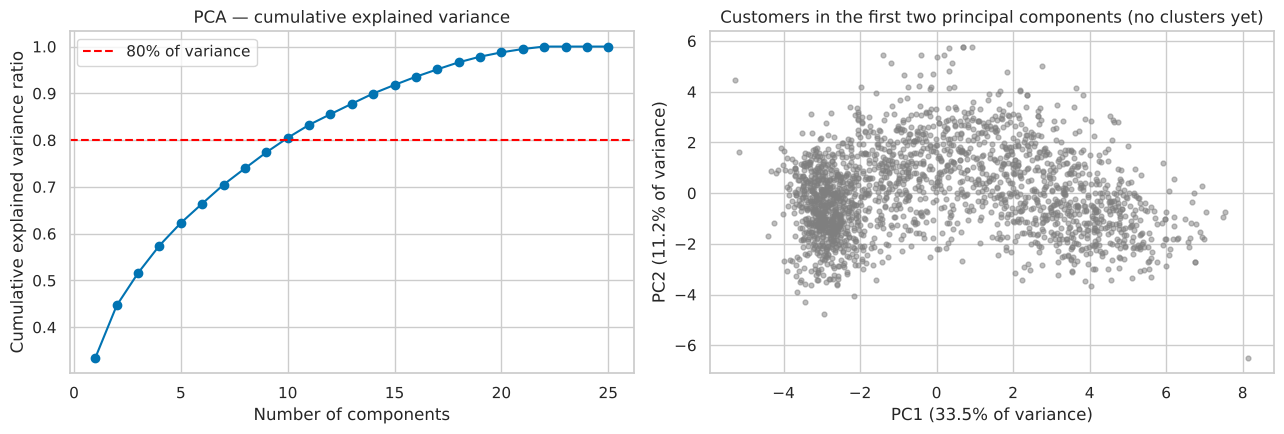

Variance explained by PC1 + PC2: 44.7%
Components needed for 80%: 10


In [15]:
# ---- 2.8 PCA — used for visualisation, and to show how much structure 2 components keep ----
pca_full = PCA(random_state=RANDOM_STATE).fit(X_scaled)
pca2 = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca2.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(range(1, len(pca_full.explained_variance_ratio_) + 1),
             np.cumsum(pca_full.explained_variance_ratio_), marker="o")
axes[0].axhline(0.8, color="red", linestyle="--", label="80% of variance")
axes[0].set_title("PCA — cumulative explained variance")
axes[0].set_xlabel("Number of components"); axes[0].set_ylabel("Cumulative explained variance ratio")
axes[0].legend()

axes[1].scatter(X_pca[:, 0], X_pca[:, 1], s=12, alpha=0.5, color="tab:grey")
axes[1].set_title("Customers in the first two principal components (no clusters yet)")
axes[1].set_xlabel(f"PC1 ({pca2.explained_variance_ratio_[0]:.1%} of variance)")
axes[1].set_ylabel(f"PC2 ({pca2.explained_variance_ratio_[1]:.1%} of variance)")
plt.tight_layout(); plt.show()

print("Variance explained by PC1 + PC2: %.1f%%" % (100 * pca2.explained_variance_ratio_.sum()))
print("Components needed for 80%%: %d" % (np.argmax(np.cumsum(pca_full.explained_variance_ratio_) >= 0.8) + 1))

**📝 What this shows:** The first two components keep 44.7% of the variance (33.5% and 11.2%) and ten of the 25 are needed to reach 80%, so the PCA scatter plots below are a readable summary of the structure, not the whole of it.

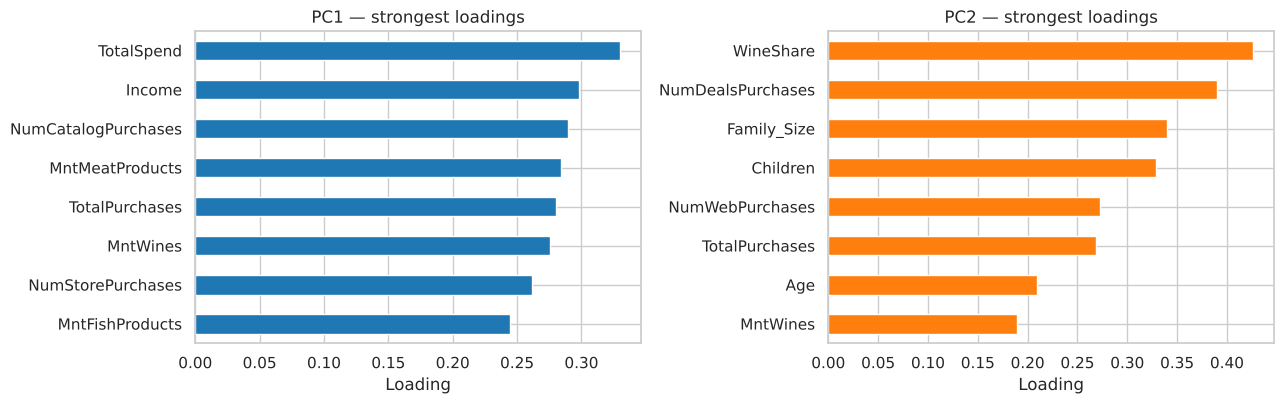

In [16]:
# ---- 2.9 What do the first two principal components actually mean? ----
loadings = pd.DataFrame(pca2.components_.T, index=X.columns, columns=["PC1", "PC2"])
top_pc1 = loadings["PC1"].abs().sort_values(ascending=False).head(8).index
top_pc2 = loadings["PC2"].abs().sort_values(ascending=False).head(8).index

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
loadings.loc[top_pc1, "PC1"].sort_values().plot(kind="barh", ax=axes[0], color="tab:blue")
axes[0].set_title("PC1 — strongest loadings"); axes[0].set_xlabel("Loading")
loadings.loc[top_pc2, "PC2"].sort_values().plot(kind="barh", ax=axes[1], color="tab:orange")
axes[1].set_title("PC2 — strongest loadings"); axes[1].set_xlabel("Loading")
plt.tight_layout(); plt.show()

**📝 What this shows:** PC1 is a pure customer-value axis — total spend, income, catalogue purchases and meat all load on it positively — while PC2 separates deal-hunting families (wine share, deals purchases, family size, children) from everyone else.

In [17]:
# ---- 2.10 Shared metric helper for the clustering track ----
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

def cluster_metrics(X_mat, labels):
    # All three are MANDATORY for this track. None of them uses the ground-truth labels.
    #   Silhouette        : -1 to 1, higher is better (separation vs cohesion)
    #   Davies-Bouldin    : 0 upwards, LOWER is better (average similarity between a cluster and its closest neighbour)
    #   Calinski-Harabasz : higher is better (between-cluster vs within-cluster dispersion)
    k = len(set(labels)) - (1 if -1 in labels else 0)
    return {
        "n_clusters": k,
        "Silhouette": silhouette_score(X_mat, labels),
        "Davies_Bouldin": davies_bouldin_score(X_mat, labels),
        "Calinski_Harabasz": calinski_harabasz_score(X_mat, labels),
    }

---
# BLOCK 3 — Clustering Track: K-Means (Review 2, Section B)

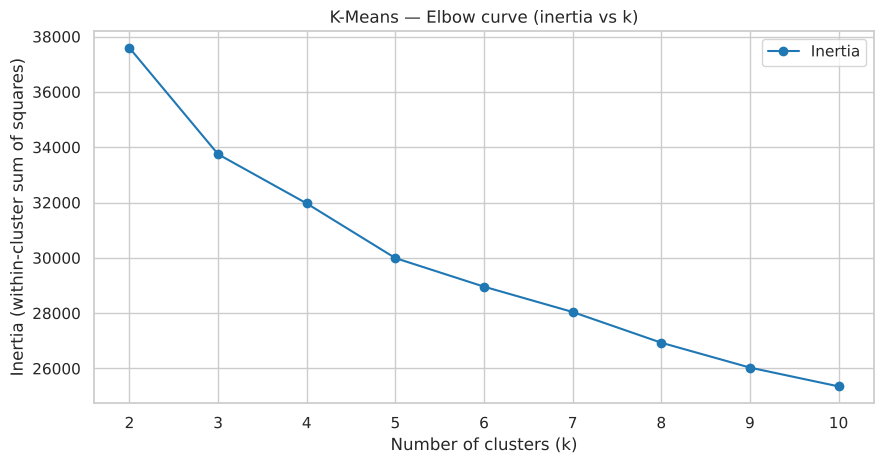

Reduction in inertia gained by adding each next cluster:
2    3843.6
3    1779.8
4    1974.9
5    1032.8
6     915.7
7    1110.7
8     899.4
9     679.2


In [18]:
# ============================================================
# BLOCK 3 : CLUSTERING — K-MEANS
# ============================================================
import time
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_samples

# ---- 3.1 Elbow curve: inertia against k (B2 requirement) ----
# Inertia = total squared distance from each point to its centroid. It always falls as k rises,
# so we look for the 'elbow' where the fall slows down, not for the minimum.
k_range = range(2, 11)
inertia, rows = [], []
for k in k_range:
    km_k = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    inertia.append(km_k.inertia_)
    rows.append({"k": k, "inertia": km_k.inertia_, **cluster_metrics(X_scaled, km_k.labels_)})
k_df = pd.DataFrame(rows).set_index("k").drop(columns="n_clusters")

plt.figure(figsize=(9, 4.8))
plt.plot(list(k_range), inertia, marker="o", color="tab:blue", label="Inertia")
plt.title("K-Means — Elbow curve (inertia vs k)")
plt.xlabel("Number of clusters (k)"); plt.ylabel("Inertia (within-cluster sum of squares)")
plt.xticks(list(k_range)); plt.legend(); plt.tight_layout(); plt.show()

# the drop between consecutive k values makes the elbow easier to read than the curve itself
drop = pd.Series(inertia, index=list(k_range)).diff(-1).dropna()
print("Reduction in inertia gained by adding each next cluster:")
print(drop.round(1).to_string())

**📝 What this shows:** The curve bends hardest at k=2: the second cluster removes 3,844 of inertia against 1,780 for the third, and past k=5 each extra cluster buys under 1,000.

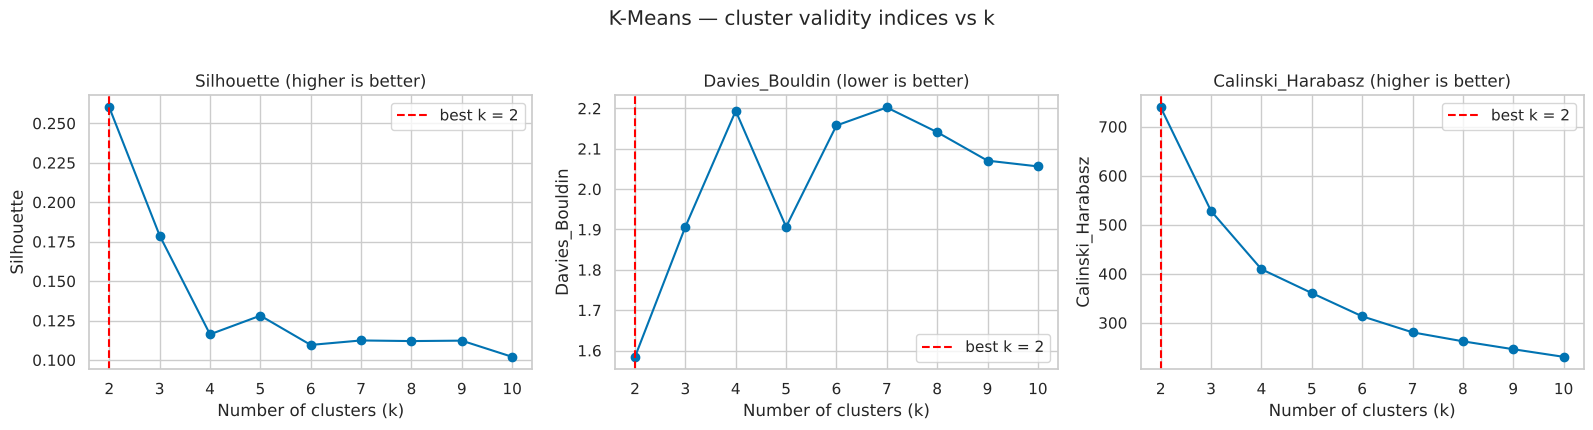

,inertia,Silhouette,Davies_Bouldin,Calinski_Harabasz
k,,,,
2,37589.3955,0.2600,1.5843,739.1064
3,33745.7675,0.1788,1.9067,527.8492
4,31965.9991,0.1163,2.1938,409.2264
5,29991.1105,0.1281,1.9065,360.5860
6,28958.3021,0.1096,2.1577,313.1695
7,28042.5714,0.1124,2.2024,280.4674
8,26931.9000,0.1120,2.1412,262.2046
9,26032.5183,0.1123,2.0706,246.0402
10,25353.3232,0.1020,2.0563,230.5144


In [19]:
# ---- 3.2 The three mandatory indices across k ----
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, (col, better) in zip(axes, [("Silhouette", "higher is better"),
                                    ("Davies_Bouldin", "lower is better"),
                                    ("Calinski_Harabasz", "higher is better")]):
    ax.plot(k_df.index, k_df[col], marker="o")
    best_k = k_df[col].idxmin() if col == "Davies_Bouldin" else k_df[col].idxmax()
    ax.axvline(best_k, color="red", linestyle="--", label=f"best k = {best_k}")
    ax.set_title(f"{col} ({better})")
    ax.set_xlabel("Number of clusters (k)"); ax.set_ylabel(col); ax.legend()
plt.suptitle("K-Means — cluster validity indices vs k", y=1.02)
plt.tight_layout(); plt.show()
k_df.round(4)

**📝 What this shows:** All three indices agree on k=2 — silhouette peaks at 0.260, Davies-Bouldin bottoms out at 1.584 and Calinski-Harabasz tops out at 739 — and every one of them gets worse from k=3 onwards.

**Choosing k.** The three indices do not always agree, so the choice is made on the balance of them plus whether the
resulting segments are usable by a marketing team — a point the rubric's viva section asks about directly.

In [20]:
# ---- 3.3 Fit the chosen K-Means model ----
BEST_K = int(k_df["Silhouette"].idxmax())
print("k chosen from the silhouette score:", BEST_K)

start = time.time()
kmeans = KMeans(n_clusters=BEST_K, n_init=20, random_state=RANDOM_STATE).fit(X_scaled)
print(f"Fit time: {time.time() - start:.2f} s | iterations: {kmeans.n_iter_}")

df["KMeans_Cluster"] = kmeans.labels_
kmeans_scores = cluster_metrics(X_scaled, kmeans.labels_)
print("Cluster sizes:", df["KMeans_Cluster"].value_counts().sort_index().to_dict())
pd.Series(kmeans_scores).round(4)

k chosen from the silhouette score: 2


Fit time: 3.30 s | iterations: 11


Cluster sizes: {0: 842, 1: 1205}


n_clusters             2.0000
Silhouette             0.2600
Davies_Bouldin         1.5843
Calinski_Harabasz    739.1064
dtype: float64

## The statistically best k is not always the most useful k

All three indices point at the same small number of clusters, and that answer is the one reported. But a marketing
team asking for segments usually wants more than two. The cell below fits the finer segmentation as well and shows
what it costs in cluster quality and what it buys in detail — the kind of trade-off the viva asks about.

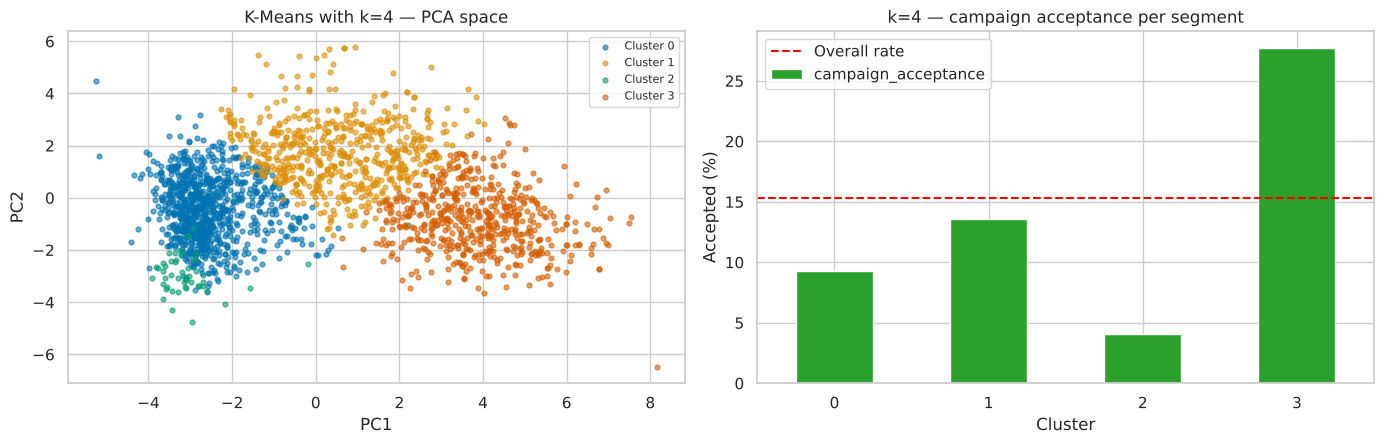

                            n_clusters  Silhouette  Davies_Bouldin  Calinski_Harabasz
Reported model (k=2)                 2      0.2600          1.5843           739.1064
Business alternative (k=4)           4      0.1966          1.6314           424.1447


,customers,Income,TotalSpend,Children,Age,WineShare,WebVisits,Deals,campaign_acceptance
KMeans_Alt,,,,,,,,,
0,892,35584.2,97.5,1.3,42.8,0.4,6.4,2.0,9.3
1,558,57332.5,716.0,1.2,48.8,0.6,5.9,3.9,13.6
2,49,19913.3,83.9,0.7,36.2,0.1,6.9,1.9,4.1
3,548,74966.2,1368.2,0.2,45.9,0.4,2.9,1.3,27.7


In [21]:
# ---- 3.3b The business alternative: a finer segmentation ----
ALT_K = 4
kmeans_alt = KMeans(n_clusters=ALT_K, n_init=20, random_state=RANDOM_STATE).fit(X_scaled)
df["KMeans_Alt"] = kmeans_alt.labels_

compare_k = pd.DataFrame([cluster_metrics(X_scaled, kmeans.labels_),
                          cluster_metrics(X_scaled, kmeans_alt.labels_)],
                         index=[f"Reported model (k={BEST_K})", f"Business alternative (k={ALT_K})"])

alt_profile = df.groupby("KMeans_Alt").agg(
    customers=("Income", "size"), Income=("Income", "mean"), TotalSpend=("TotalSpend", "mean"),
    Children=("Children", "mean"), Age=("Age", "mean"), WineShare=("WineShare", "mean"),
    WebVisits=("NumWebVisitsMonth", "mean"), Deals=("NumDealsPurchases", "mean"),
    campaign_acceptance=("Response", "mean"))      # label used for interpretation only
alt_profile["campaign_acceptance"] *= 100

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for c in sorted(df["KMeans_Alt"].unique()):
    m = (df["KMeans_Alt"] == c).values
    axes[0].scatter(X_pca[m, 0], X_pca[m, 1], s=12, alpha=0.6, label=f"Cluster {c}")
axes[0].set_title(f"K-Means with k={ALT_K} — PCA space")
axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2"); axes[0].legend(fontsize=8)

alt_profile["campaign_acceptance"].plot(kind="bar", ax=axes[1], color="tab:green")
axes[1].axhline(df["Response"].mean() * 100, color="red", linestyle="--", label="Overall rate")
axes[1].set_title(f"k={ALT_K} — campaign acceptance per segment")
axes[1].set_xlabel("Cluster"); axes[1].set_ylabel("Accepted (%)")
axes[1].tick_params(axis="x", rotation=0); axes[1].legend()
plt.tight_layout(); plt.show()

print(compare_k.round(4).to_string())
alt_profile.round(1)

**📝 What this shows:** Four segments cost about a quarter of the silhouette (0.197 against 0.260) and buy a far more usable picture, running from a 4.1%-accepting low-income group to a 27.7%-accepting affluent one.

## B3 — Cluster visualisation (PCA, silhouette, t-SNE)

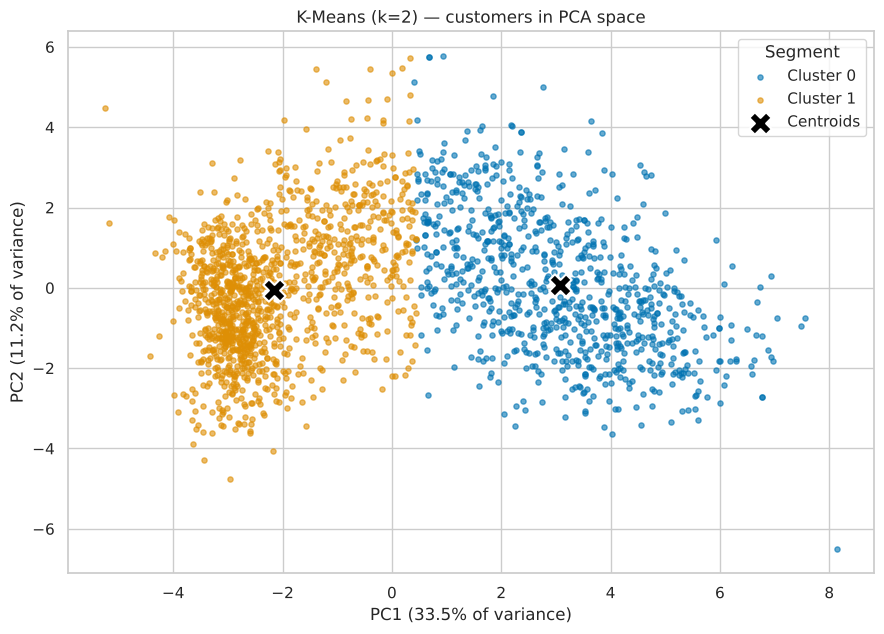

In [22]:
# ---- 3.4 PCA-reduced 2D scatter with the centroids marked (mandatory) ----
centroids_pca = pca2.transform(kmeans.cluster_centers_)

plt.figure(figsize=(9, 6.5))
for c in sorted(df["KMeans_Cluster"].unique()):
    m = df["KMeans_Cluster"] == c
    plt.scatter(X_pca[m.values, 0], X_pca[m.values, 1], s=14, alpha=0.6, label=f"Cluster {c}")
plt.scatter(centroids_pca[:, 0], centroids_pca[:, 1], s=260, c="black", marker="X",
            edgecolors="white", linewidths=1.5, label="Centroids")
plt.title(f"K-Means (k={BEST_K}) — customers in PCA space")
plt.xlabel(f"PC1 ({pca2.explained_variance_ratio_[0]:.1%} of variance)")
plt.ylabel(f"PC2 ({pca2.explained_variance_ratio_[1]:.1%} of variance)")
plt.legend(title="Segment"); plt.tight_layout(); plt.show()

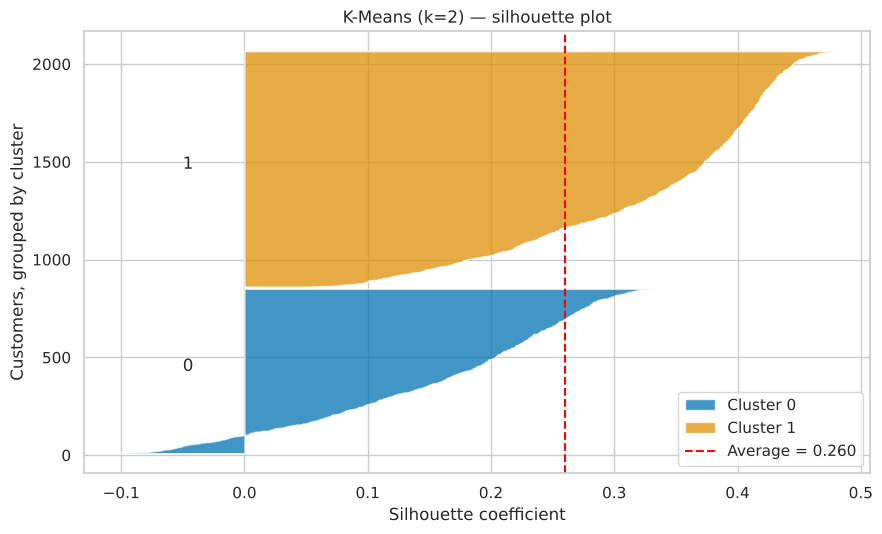

Customers with a NEGATIVE silhouette (probably in the wrong cluster): 93 of 2047 (4.5%)


In [23]:
# ---- 3.5 Silhouette plot: how well each individual customer fits its cluster ----
sample_sil = silhouette_samples(X_scaled, kmeans.labels_)

plt.figure(figsize=(9, 5.5))
y_lower = 10
for c in sorted(df["KMeans_Cluster"].unique()):
    vals = np.sort(sample_sil[kmeans.labels_ == c])
    y_upper = y_lower + len(vals)
    plt.fill_betweenx(np.arange(y_lower, y_upper), 0, vals, alpha=0.75, label=f"Cluster {c}")
    plt.text(-0.05, y_lower + 0.5 * len(vals), str(c))
    y_lower = y_upper + 10
plt.axvline(kmeans_scores["Silhouette"], color="red", linestyle="--",
            label=f"Average = {kmeans_scores['Silhouette']:.3f}")
plt.title(f"K-Means (k={BEST_K}) — silhouette plot")
plt.xlabel("Silhouette coefficient"); plt.ylabel("Customers, grouped by cluster")
plt.legend(loc="lower right"); plt.tight_layout(); plt.show()

print("Customers with a NEGATIVE silhouette (probably in the wrong cluster): %d of %d (%.1f%%)"
      % ((sample_sil < 0).sum(), len(sample_sil), 100 * (sample_sil < 0).mean()))

**📝 What this shows:** Only 93 of 2,047 customers (4.5%) have a negative silhouette, so nearly everyone sits closer to their own cluster than to the other one, even though the 0.26 average is modest.

t-SNE time: 45.9 s


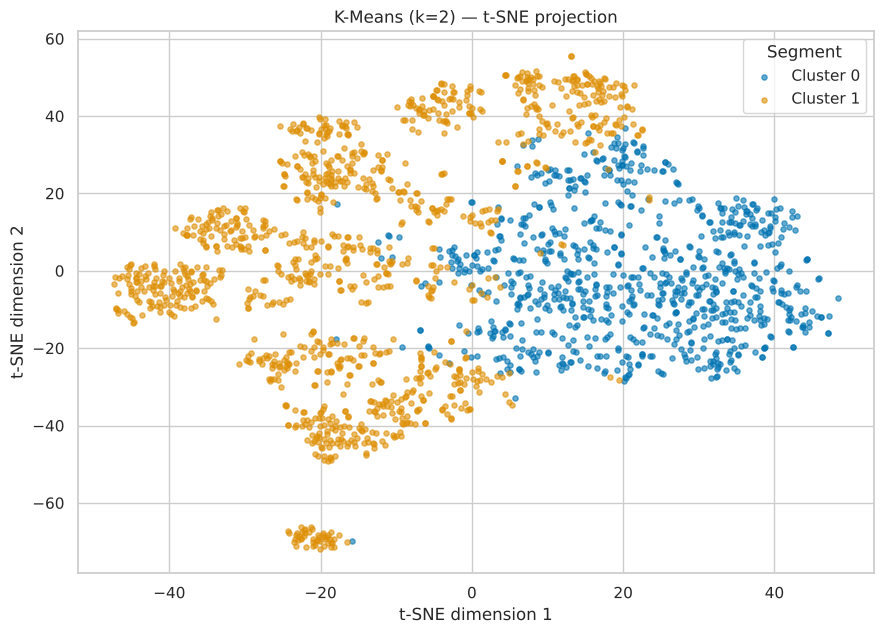

In [24]:
# ---- 3.6 t-SNE view (encouraged by the rubric) ----
# t-SNE preserves local neighbourhoods rather than global distances, so it often separates
# groups that PCA leaves overlapping. The axes themselves carry no meaning.
start = time.time()
tsne = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=RANDOM_STATE)
X_tsne = tsne.fit_transform(X_scaled)
print(f"t-SNE time: {time.time() - start:.1f} s")

plt.figure(figsize=(9, 6.5))
for c in sorted(df["KMeans_Cluster"].unique()):
    m = (df["KMeans_Cluster"] == c).values
    plt.scatter(X_tsne[m, 0], X_tsne[m, 1], s=14, alpha=0.6, label=f"Cluster {c}")
plt.title(f"K-Means (k={BEST_K}) — t-SNE projection")
plt.xlabel("t-SNE dimension 1"); plt.ylabel("t-SNE dimension 2")
plt.legend(title="Segment"); plt.tight_layout(); plt.show()

**📝 What this shows:** t-SNE pulls the two groups apart far more cleanly than PCA manages, and the boundary falls in the same place — a sign the split is real rather than an artefact of the linear projection.

## Interpreting the segments (K-Means)

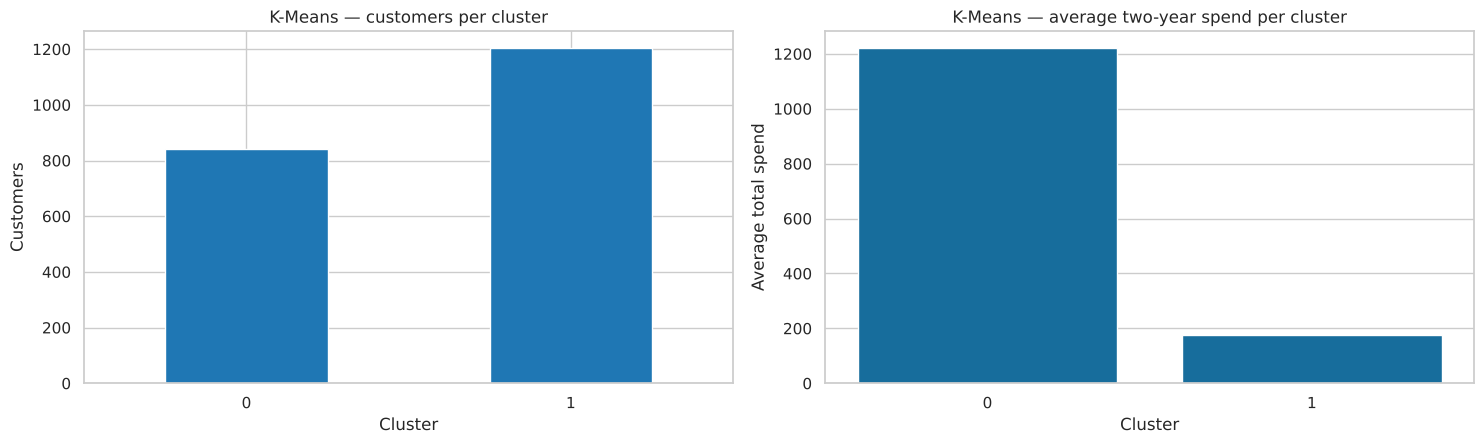

,customers,Age,Income,Tenure_days,Recency,Children,Family_Size,TotalSpend,TotalPurchases,AvgOrderValue,WineShare,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumDealsPurchases,NumWebVisitsMonth
KMeans_Cluster,,,,,,,,,,,,,,,,
0,842,47.1,70521.5,540.9,49.3,0.5,2.1,1222.1,21.7,61.0,0.5,5.9,5.2,8.5,2.1,3.8
1,1205,43.7,38515.2,492.2,48.7,1.3,2.9,175.4,10.1,14.1,0.4,2.9,0.9,3.9,2.5,6.4


In [25]:
# ---- 3.7 Cluster sizes and average profile ----
profile_cols = ["Age", "Income", "Tenure_days", "Recency", "Children", "Family_Size",
                "TotalSpend", "TotalPurchases", "AvgOrderValue", "WineShare",
                "NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases",
                "NumDealsPurchases", "NumWebVisitsMonth"]
profile = df.groupby("KMeans_Cluster")[profile_cols].mean()
profile.insert(0, "customers", df["KMeans_Cluster"].value_counts().sort_index())

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
profile["customers"].plot(kind="bar", ax=axes[0], color="tab:blue")
axes[0].set_title("K-Means — customers per cluster")
axes[0].set_xlabel("Cluster"); axes[0].set_ylabel("Customers"); axes[0].tick_params(axis="x", rotation=0)

sns.barplot(data=df, x="KMeans_Cluster", y="TotalSpend", ax=axes[1], errorbar=None)
axes[1].set_title("K-Means — average two-year spend per cluster")
axes[1].set_xlabel("Cluster"); axes[1].set_ylabel("Average total spend")
plt.tight_layout(); plt.show()

profile.round(1)

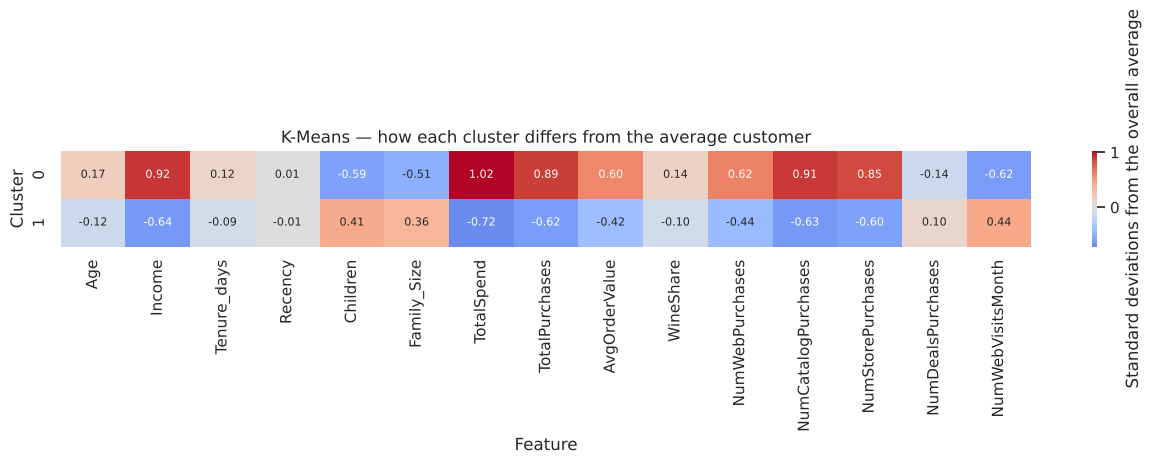

In [26]:
# ---- 3.8 Profile heatmap (z-scores, so every feature is on the same scale) ----
z = (profile[profile_cols] - df[profile_cols].mean()) / df[profile_cols].std()
plt.figure(figsize=(13, 3.6))
sns.heatmap(z, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            cbar_kws={"label": "Standard deviations from the overall average"}, annot_kws={"size": 8})
plt.title("K-Means — how each cluster differs from the average customer")
plt.xlabel("Feature"); plt.ylabel("Cluster")
plt.tight_layout(); plt.show()

**📝 What this shows:** Cluster 0 (842 customers) earns 70,500 and spends 1,222 over two years; cluster 1 (1,205 customers) earns 38,500, spends 175, has more children at home and visits the website nearly twice as often.

## Post-hoc validation against the held-back labels

The campaign columns were kept out of the feature matrix. Bringing them back **now** is the honest test of whether the
segmentation means anything: if the clusters were noise, campaign acceptance would be flat across them.

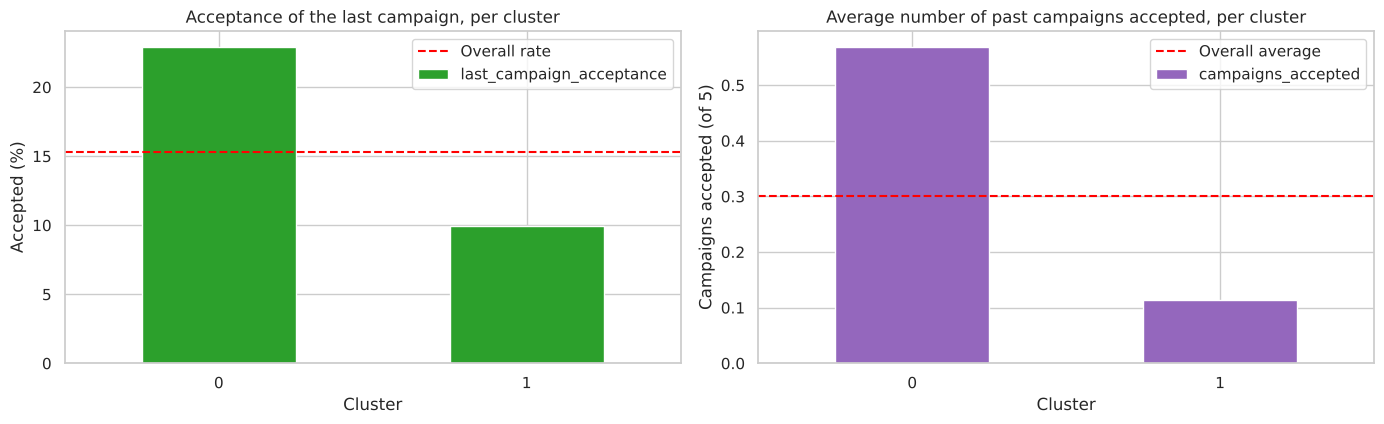

Education mix per cluster (%):
Education_level  Graduate  Master   PhD  Undergraduate
KMeans_Cluster                                        
0                    52.4    23.6  23.9            0.1
1                    48.6    27.1  20.2            4.0


,customers,last_campaign_acceptance,campaigns_accepted,complaint_rate
KMeans_Cluster,,,,
0,842,22.922,0.569,0.008
1,1205,9.959,0.115,0.010


In [27]:
# ---- 3.9 Campaign response per cluster (labels used ONLY here, after fitting) ----
resp = df.groupby("KMeans_Cluster").agg(
    customers=("Response", "size"),
    last_campaign_acceptance=("Response", "mean"),
    campaigns_accepted=("CampaignsAccepted", "mean"),
    complaint_rate=("Complain", "mean"),
)
resp["last_campaign_acceptance"] *= 100

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
resp["last_campaign_acceptance"].plot(kind="bar", ax=axes[0], color="tab:green")
axes[0].axhline(df["Response"].mean() * 100, color="red", linestyle="--", label="Overall rate")
axes[0].set_title("Acceptance of the last campaign, per cluster")
axes[0].set_xlabel("Cluster"); axes[0].set_ylabel("Accepted (%)")
axes[0].tick_params(axis="x", rotation=0); axes[0].legend()

resp["campaigns_accepted"].plot(kind="bar", ax=axes[1], color="tab:purple")
axes[1].axhline(df["CampaignsAccepted"].mean(), color="red", linestyle="--", label="Overall average")
axes[1].set_title("Average number of past campaigns accepted, per cluster")
axes[1].set_xlabel("Cluster"); axes[1].set_ylabel("Campaigns accepted (of 5)")
axes[1].tick_params(axis="x", rotation=0); axes[1].legend()
plt.tight_layout(); plt.show()

print("Education mix per cluster (%):")
print((pd.crosstab(df["KMeans_Cluster"], df["Education_level"], normalize="index") * 100).round(1))
resp.round(3)

**📝 What this shows:** The split holds up against the labels it never saw: 22.9% of cluster 0 accepted the last campaign against 10.0% of cluster 1, and cluster 0 has accepted five times as many campaigns on average (0.57 against 0.12).

In [28]:
# ---- 3.10 Save results for the clustering comparison (deliverable D7) ----
os.makedirs("../results", exist_ok=True)
RESULTS_FILE = "../results/clustering_results.csv"
MODEL_NAME = f"K-Means (k={BEST_K})"

row = pd.DataFrame([{"Model": MODEL_NAME, "Algorithm": "K-Means", **kmeans_scores,
                     "Parameters": f"n_clusters={BEST_K}, n_init=20"}])
if os.path.exists(RESULTS_FILE):
    old = pd.read_csv(RESULTS_FILE)
    row = pd.concat([old[old["Algorithm"] != "K-Means"], row], ignore_index=True)
row.to_csv(RESULTS_FILE, index=False)

# the cluster labels are saved too, so notebook 23 can compare the two algorithms directly
df[["KMeans_Cluster"]].to_csv("../results/kmeans_labels.csv", index=False)
row.round(4)

,Model,Algorithm,n_clusters,Silhouette,Davies_Bouldin,Calinski_Harabasz,Parameters
0,K-Means (k=2),K-Means,2,0.26,1.5843,739.1064,"n_clusters=2, n_init=20"


## Summary

**📝 In short:** K-Means splits the customer base in two — an affluent, high-spending, catalogue-and-store half and a lower-income, child-heavy, deal-hunting half — and the half it picked out without ever seeing campaign data is the half that accepts campaigns twice as often.